In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [3]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_128_train/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(128,128),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_128_test/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(128,128),
    seed=42,
    shuffle=False,
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 4382 files belonging to 2 classes.
Using 3506 files for training.
Using 876 files for validation.
Found 1082 files belonging to 2 classes.


In [4]:
# #Correct model
model = keras.models.Sequential()
model.add(keras.Input(shape=(128,128,3)))

model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=64, kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=128, kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())

model.add(layers.Flatten())

model.add(layers.Dense(units=128, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=2, activation='softmax'))

# model = keras.models.Sequential()
# model.add(keras.Input(shape=(128,128,3)))
# model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))

# model.add(layers.Flatten())

# model.add(layers.Dense(units=64, activation='relu'))
# model.add(layers.Dense(units=1, activation='sigmoid'))

model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=5)

In [5]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    class_weight={0: 0.65, 1: 1}
    )

Epoch 1/50
220/220 [==============================] - 9s 21ms/step - loss: 0.6665 - categorical_accuracy: 0.5833 - val_loss: 2.9149 - val_categorical_accuracy: 0.7009
Epoch 2/50
220/220 [==============================] - 4s 19ms/step - loss: 0.5290 - categorical_accuracy: 0.6423 - val_loss: 0.6242 - val_categorical_accuracy: 0.6838
Epoch 3/50
220/220 [==============================] - 4s 19ms/step - loss: 0.4902 - categorical_accuracy: 0.6825 - val_loss: 0.7690 - val_categorical_accuracy: 0.7009
Epoch 4/50
220/220 [==============================] - 4s 19ms/step - loss: 0.4312 - categorical_accuracy: 0.7710 - val_loss: 0.6553 - val_categorical_accuracy: 0.7283
Epoch 5/50
220/220 [==============================] - 4s 19ms/step - loss: 0.3352 - categorical_accuracy: 0.8303 - val_loss: 0.3345 - val_categorical_accuracy: 0.8767
Epoch 6/50
220/220 [==============================] - 4s 19ms/step - loss: 0.2562 - categorical_accuracy: 0.8896 - val_loss: 0.3230 - val_categorical_accuracy: 0.880

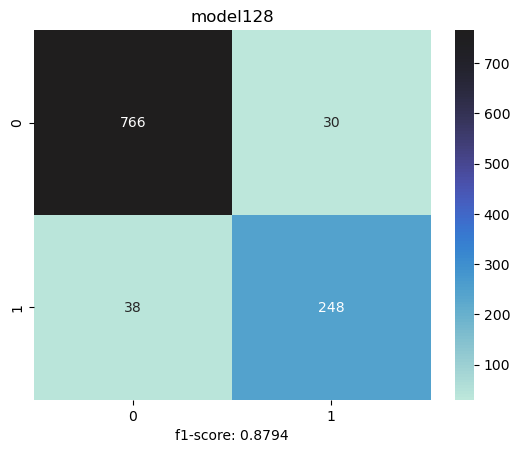

In [7]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model128')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model128.png')
plt.show()

In [8]:
model.save('./trained_models/model128_class')

INFO:tensorflow:Assets written to: ./trained_models/model128_cat\assets


INFO:tensorflow:Assets written to: ./trained_models/model128_cat\assets


In [4]:
model128 = keras.models.load_model('./trained_models/model128_test')
model128.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 32)        4736      
                                                                 
 batch_normalization (BatchN  (None, 64, 64, 32)       128       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 batch_normalization_1 (Batc  (None, 32, 32, 64)       256       
 hNormalization)                                                 
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 64)        36928     
                                                                 
 batch_normalization_2 (Batc  (None, 32, 32, 64)       2

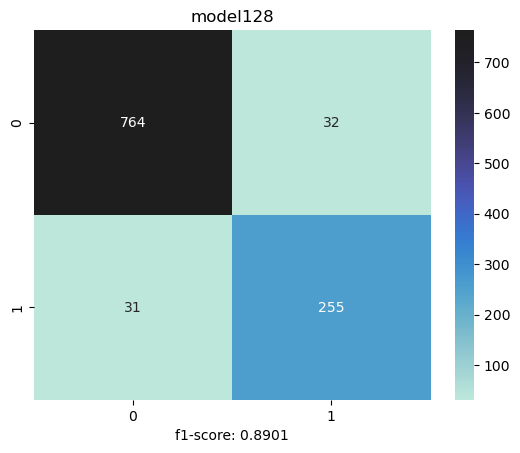

In [7]:
array = test_model(model128, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model128')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model128.png')
plt.show()